In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total original images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Augmentation Pipeline & DataFrame Expansion Before Split
# ================================================================
aug_transform = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5)
])

# 
AUG_COPIES = 1
df_augmented = pd.concat([df] + [df.copy() for _ in range(AUG_COPIES)], ignore_index=True)
print(f"Total images after DataFrame expansion before split: {len(df_augmented)}")

# ================================================================
# 4. Random Dataset Split (Without Stratify)
# ================================================================
train_and_val, test_df = train_test_split(
    df_augmented, test_size=TEST_RATIO, random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 5. Image Preprocessing Transformation & Generator
# ================================================================
def load_image(path, transform=None):
    img = cv2.imread(path)
    if img is None:
        img = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return convnext_preprocess(img.astype(np.float32))

class ConvNeXtOnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = ConvNeXtOnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=aug_transform, shuffle=True)
val_gen = ConvNeXtOnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=None, shuffle=False)
test_gen = ConvNeXtOnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=None, shuffle=False)

# ================================================================
# 6. Build ConvNeXtTiny Model
# ================================================================
def build_convnext_tiny(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # ConvNeXtTiny Backbone
    base_model = ConvNeXtTiny(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='ConvNeXtTiny_Only')
    return model, base_model

model, base_model = build_convnext_tiny(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "convnext_tiny_expanded_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting ConvNeXtTiny Training (Expanded Data without Stratify) <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 19221.15it/s]
/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Total original images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Total images after DataFrame expansion before split: 20030
Train samples: 14020 | Val samples: 3005 | Test samples: 3005
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ConvNeXtTiny_Only"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 27,827,047 (106.15 MB)

 Trainable params: 27,827,047 (106.15 MB)

... (13 outputs left out)


Epoch 13: finished saving model to convnext_tiny_expanded_best.h5
439/439 ━━━━━━━━━━━━━━━━━━━━ 328s 746ms/step - accuracy: 0.9864 - loss: 0.0400 - val_accuracy: 0.9694 - val_loss: 0.1139 - learning_rate: 1.0000e-04
Epoch 14/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9900 - loss: 0.0280
Epoch 14: val_accuracy did not improve from 0.96938
439/439 ━━━━━━━━━━━━━━━━━━━━ 324s 738ms/step - accuracy: 0.9881 - loss: 0.0347 - val_accuracy: 0.9664 - val_loss: 0.1263 - learning_rate: 1.0000e-04
Epoch 15/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - accuracy: 0.9897 - loss: 0.0318
Epoch 15: val_accuracy did not improve from 0.96938
439/439 ━━━━━━━━━━━━━━━━━━━━ 325s 740ms/step - accuracy: 0.9900 - loss: 0.0291 - val_accuracy: 0.9587 - val_loss: 0.1779 - learning_rate: 1.0000e-04
Epoch 16/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9905 - loss: 0.0308
Epoch 16: val_accuracy did not improve from 0.96938
439/439 ━━━━━━━━━━━━━━━━━━━━ 324s 738ms/step - accuracy: 0.9914


Epoch 17: finished saving model to convnext_tiny_expanded_best.h5
439/439 ━━━━━━━━━━━━━━━━━━━━ 327s 743ms/step - accuracy: 0.9895 - loss: 0.0305 - val_accuracy: 0.9697 - val_loss: 0.1134 - learning_rate: 1.0000e-04
Epoch 18/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9923 - loss: 0.0220
Epoch 18: val_accuracy improved from 0.96972 to 0.97438, saving model to convnext_tiny_expanded_best.h5



Epoch 18: finished saving model to convnext_tiny_expanded_best.h5
439/439 ━━━━━━━━━━━━━━━━━━━━ 327s 745ms/step - accuracy: 0.9921 - loss: 0.0229 - val_accuracy: 0.9744 - val_loss: 0.1119 - learning_rate: 1.0000e-04
Epoch 19/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9924 - loss: 0.0226
Epoch 20: val_accuracy did not improve from 0.97438
439/439 ━━━━━━━━━━━━━━━━━━━━ 326s 741ms/step - accuracy: 0.9922 - loss: 0.0251 - val_accuracy: 0.9681 - val_loss: 0.1240 - learning_rate: 1.0000e-04
Epoch 21/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9938 - loss: 0.0191
Epoch 21: val_accuracy did not improve from 0.97438
439/439 ━━━━━━━━━━━━━━━━━━━━ 326s 743ms/step - accuracy: 0.9933 - loss: 0.0216 - val_accuracy: 0.9604 - val_loss: 0.1950 - learning_rate: 1.0000e-04
Epoch 22/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9902 - loss: 0.0302
Epoch 22: val_accuracy did not improve from 0.97438
439/439 ━━━━━━━━━━━━━━━━━━━━ 324s 737ms/step - accuracy: 0.9911


Epoch 24: finished saving model to convnext_tiny_expanded_best.h5
439/439 ━━━━━━━━━━━━━━━━━━━━ 329s 748ms/step - accuracy: 0.9975 - loss: 0.0082 - val_accuracy: 0.9810 - val_loss: 0.0885 - learning_rate: 5.0000e-05
Epoch 25/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - accuracy: 0.9958 - loss: 0.0144
Epoch 25: val_accuracy did not improve from 0.98103
439/439 ━━━━━━━━━━━━━━━━━━━━ 326s 742ms/step - accuracy: 0.9969 - loss: 0.0112 - val_accuracy: 0.9787 - val_loss: 0.0971 - learning_rate: 5.0000e-05
Epoch 26/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.9993 - loss: 0.0028
Epoch 26: val_accuracy did not improve from 0.98103
439/439 ━━━━━━━━━━━━━━━━━━━━ 327s 743ms/step - accuracy: 0.9984 - loss: 0.0041 - val_accuracy: 0.9794 - val_loss: 0.0965 - learning_rate: 5.0000e-05
Epoch 27/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - accuracy: 0.9978 - loss: 0.0058
Epoch 27: val_accuracy did not improve from 0.98103
439/439 ━━━━━━━━━━━━━━━━━━━━ 325s 740ms/step - accuracy: 0.9984

Test Accuracy: 97.94%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.8750    0.9381    0.9055        97
         bcc     0.9867    0.9673    0.9769       153
         bkl     0.9737    0.9308    0.9518       318
          df     1.0000    0.9592    0.9792        49
         mel     0.9613    0.9642    0.9627       335
          nv     0.9881    0.9925    0.9903      2007
        vasc     0.9583    1.0000    0.9787        46

    accuracy                         0.9794      3005
   macro avg     0.9633    0.9646    0.9636      3005
weighted avg     0.9796    0.9794    0.9794      3005



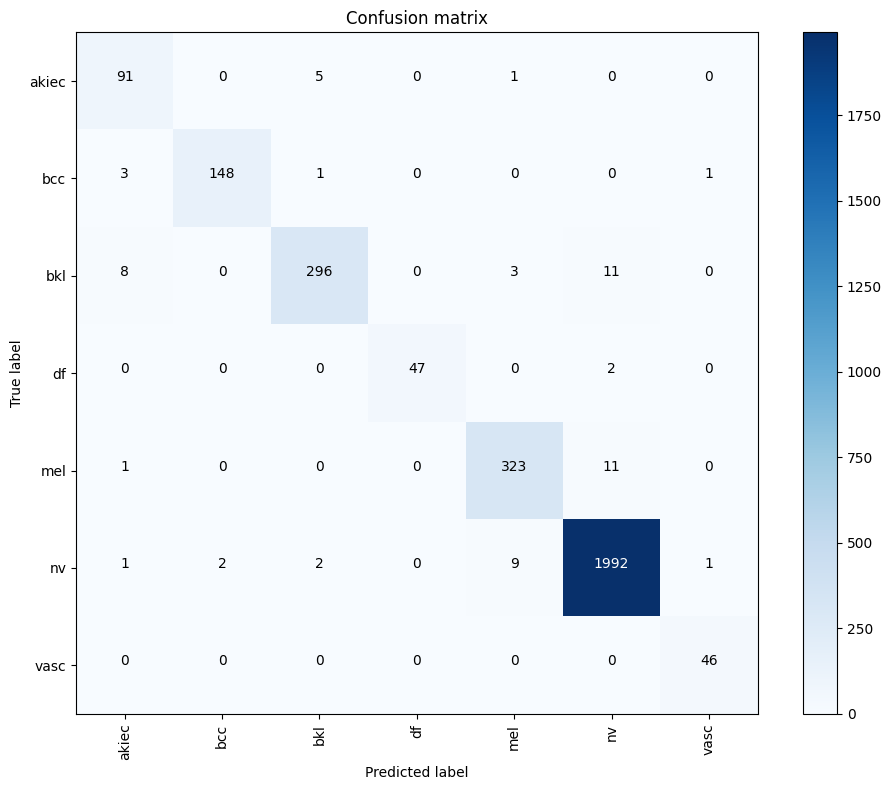

In [2]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

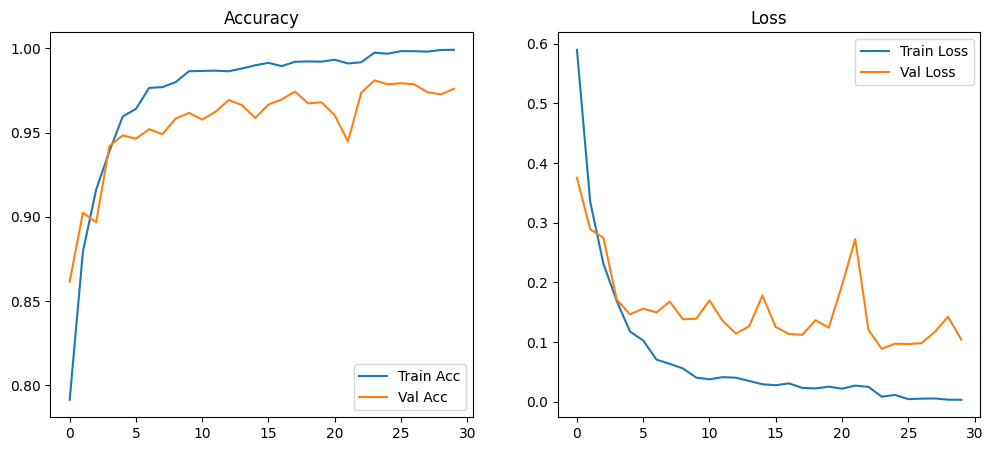

In [3]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

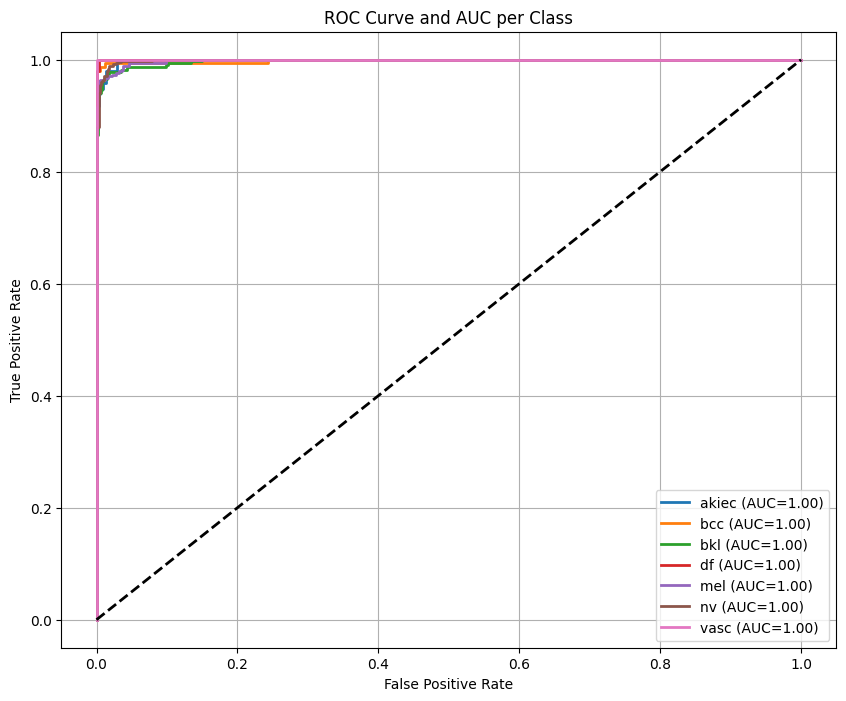

AUC for akiec: 0.9987
AUC for bcc: 0.9982
AUC for bkl: 0.9975
AUC for df: 0.9999
AUC for mel: 0.9983
AUC for nv: 0.9988
AUC for vasc: 1.0000
weighted-average AUC: 0.9993


In [4]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [5]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 97.94%
 Specificity : 99.46%
 Precision   : 97.96%
 Sensitivity : 97.94%
 F1 Score    : 97.94%
